# **Stellar Stream Tutorial | Probe Combination for Dark Matter Physics in the Era of Large Surveys**

In [8]:
from astropy import units as u
from streamsculptor.main import usys
import jax.numpy as jnp
from astropy.coordinates import SkyCoord, Galactocentric

import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)

from streamsculptor import potential
from streamsculptor import JaxCoords as jc #provides cartesian to ICRS coordinte conversion
from streamsculptor import usys
from streamsculptor import gen_stream_Chen25 #provide the Chen25 stream generation function


import diffrax #supplies the ODE solvers used to integrate orbits and generate streams
import matplotlib as mpl
import streamsculptor as ssc #provide the Chen25 stream generation function (used for unperturbed stream), 

from astropy.table import Table #reads the Gaia member data from an ECSV table
import numpy as np
import interpax  #interpolates the modelled stream'sphase-space coordinates
import equinox as eqx  #provides jax compatible utilities including jit
import tqdm #displays progress bars for longer loops


We start by converting a stream into GD-1 coordinates. To do that, first the spherical ICRS coordinates are transformed into unit cartesian vectors, then the rotation matirx is multiplied which produces coordinates in the GD-1 frame. The rotated cartesian coordinated are then transformed back to the spherical coordinates to give back phi1 and phi2

In [9]:
@jax.jit
def icrs_to_gd1(ra_rad, dec_rad):
    """
    Differentiable ra, dec --> gd1 phi1, phi2 (Koposov+2010 rotation matrix). 
    ra_rad, dec_rad in radians.
    """
    """
    Koposov+2010 rotation matrix converts from 3D ICRS to the GD-1 coordinates frame
    """
    
    R = jnp.array(
        [
            [-0.4776303088, -0.1738432154, 0.8611897727],
            [0.510844589, -0.8524449229, 0.111245042],
            [0.7147776536, 0.4930681392, 0.4959603976],
        ]
    )
                                                              #converts each (ra,dec) pair into a unit cartesian direction vector
    icrs_vec = jnp.vstack([jnp.cos(ra_rad)*jnp.cos(dec_rad),  #x-component
                           jnp.sin(ra_rad)*jnp.cos(dec_rad),  #y-component
                           jnp.sin(dec_rad)]).T               #z-component
                                                              #this gives a tabls with one row per star(N) and three columns (x,y,z). So, (N,3).

    stream_frame_vec = jnp.einsum('ij,kj->ki', R, icrs_vec)   #appies R to every vector, producing coordinates in the GD-1 oriented frame 
                                                              #einsum= Einstien Summation
    
    phi1 = jnp.arctan2(stream_frame_vec[:,1], stream_frame_vec[:,0])*180/jnp.pi #calculates the stream phase longitude with acrtan(y,x) and converts radians to degrees
    phi2 = jnp.arcsin(stream_frame_vec[:,2])*180/jnp.pi                         #calculates stream-frame lattitude with arcsin(z) and converts radians to degrees

    return phi1, phi2

@jax.jit
def get_phi12_from_stream(stream):
    """Differentiable helper: simulated stream --> phi1, phi2."""
    ra_s, dec_s, dist_ = jax.vmap(jc.simcart_to_icrs)(stream[:,:3])
    phi1_model, phi2_model = icrs_to_gd1(ra_s*jnp.pi/180, dec_s*jnp.pi/180)
    return phi1_model, phi2_model



## Generating a smooth GD-1 model simulation stream

In [10]:
prog_wtoday = jnp.array([-11.88431447,   1.61212652,   7.14988315,  -0.09253346, -0.22701121,  -0.10732978]) #location from GD1_progenitor.npy
#

**1. Making a pipefile for a new function**

A new pipeline is made so that comparisions can be made easily. 

Trying out the following potentials-
GalaMilkyWayPotential,
BovyMWPotential2014


In [11]:
def gen_stream(t_age, Msat, N_tail, t_dissolve, seed=532):
    IC = pot.integrate_orbit(w0=prog_wtoday, t0=0.0, t1=-t_age, ts=jnp.array([-t_age])).ys[0] #initial conditions
    ts = jnp.hstack([jnp.linspace(-t_age, t_dissolve, N_tail), jnp.array([0.0])])
    l, t = ssc.gen_stream_Chen25(pot_base=pot, ts=ts, prog_w0=IC, Msat=Msat,
                             key=jax.random.PRNGKey(532), method="vmap",           
                             solver=diffrax.Dopri8(), atol=1e-7, rtol=1e-7, dtmin=0.1)
    stream = jnp.vstack([l,t])
    phi1, phi2 = get_phi12_from_stream(stream)
    return np.array(phi1), np.asarray(phi2)

    #
    #

In [12]:
pot = potential.GalaMilkyWayPotential(units=usys)
#
#

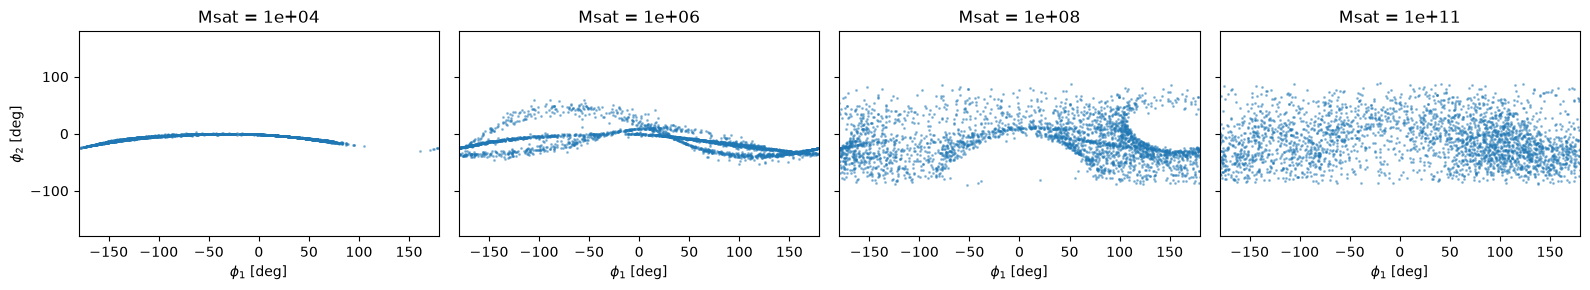

In [24]:
#Side by side
masses = [1e4, 1e6, 1e8, 1e11]
colours = ["tab:red", "tab:green", "tab:orange", "tab:blue"]

t_age = 20_000
t_dissolve = -300

N_tail = 1_500

fig, axes = plt.subplots(1, len(masses), figsize=(16, 3), sharex=True, sharey=True)
for ax, Msat in zip(axes, masses):
    phi1, phi2 = gen_stream(t_age, N_tail=N_tail, t_dissolve=t_dissolve, Msat=Msat)
    ax.scatter(phi1, phi2, s=1.2, alpha=0.4, rasterized=True)
    ax.set_title(f"Msat = {Msat:.0e}")
    ax.set_xlabel(r"$\phi_1$ [deg]")
axes[0].set_ylabel(r"$\phi_2$ [deg]")
#axes[0].set_xlim(-100, 20); axes[0].set_ylim(-10, 10)
axes[0].set_xlim(-180, 180); axes[0].set_ylim(-180, 180)
plt.tight_layout()
plt.show()
#
#

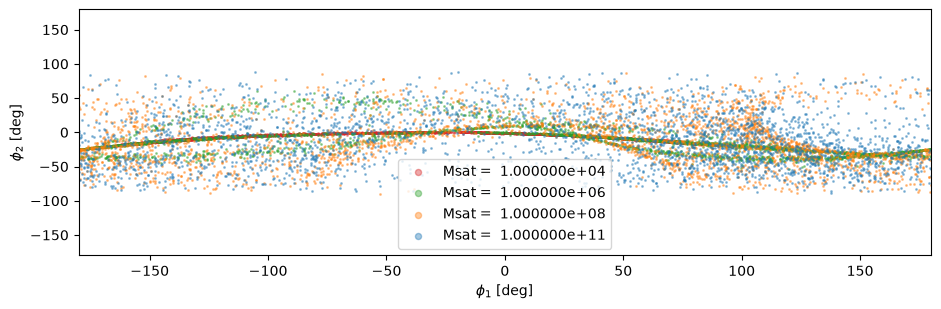

In [25]:
#Overlay
masses = [1e4, 1e6, 1e8, 1e11]
colours = ["tab:red", "tab:green", "tab:orange", "tab:blue"]

t_age = 20_000
t_dissolve = -300

N_tail = 1_500

fig, ax = plt.subplots(figsize=(11, 3.2))
for Msat, c in zip(masses, colours):
    phi1, phi2 = gen_stream(t_age, Msat=Msat, N_tail=N_tail, t_dissolve= t_dissolve)
    ax.scatter(phi1, phi2, s=1.2, color=c, alpha=0.4, label=f"Msat = {Msat: 0e}", rasterized=True)

ax.set_xlim(-180,180); ax.set_ylim(-180,180)
ax.set_xlabel(r"$\phi_1$ [deg]"); ax.set_ylabel(r"$\phi_2$ [deg]")
ax.legend(markerscale=4)
plt.show()


    

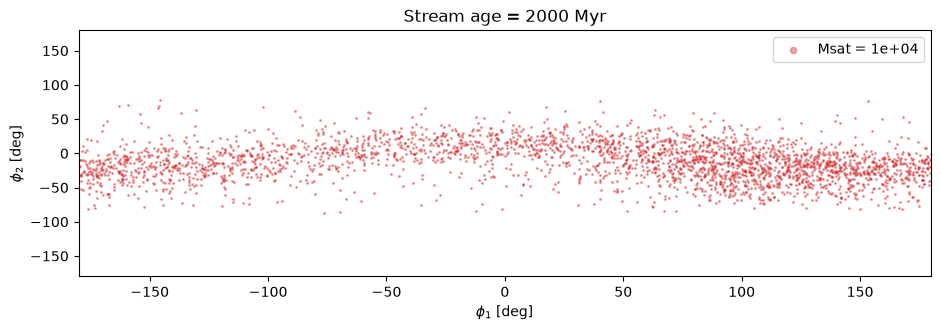

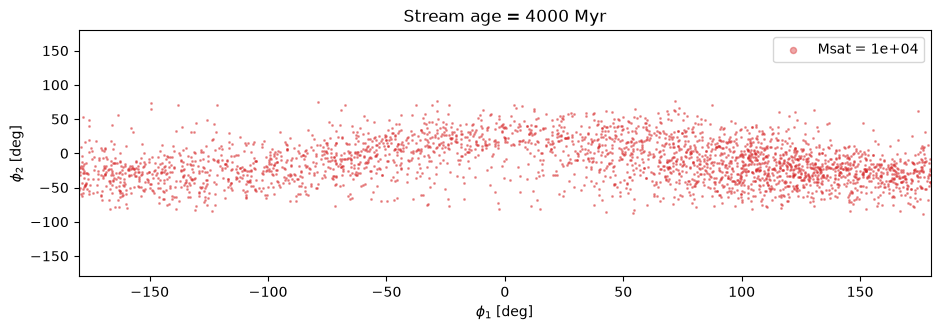

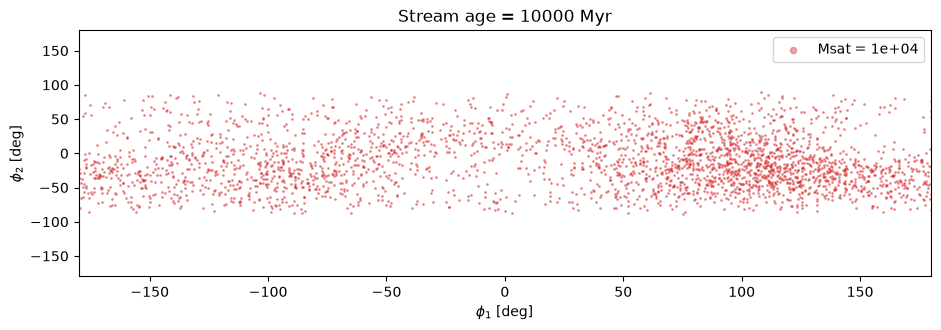

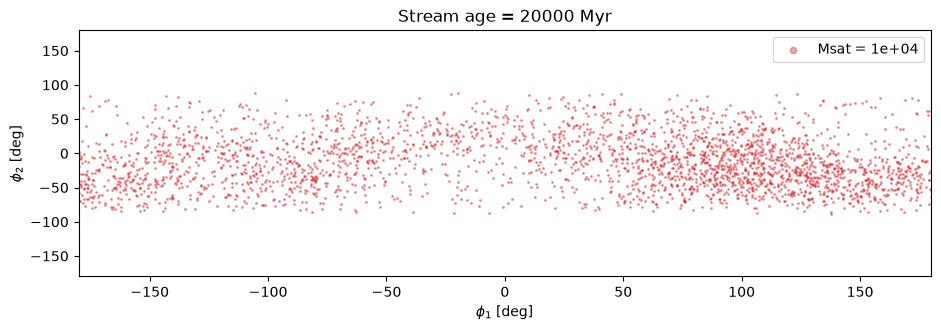

In [19]:
ages = [2000, 4000, 10000, 20000]

#fig, ax = plt.subplots(1, len(ages), figsize=(16, 3), sharex=True, sharey=True)
for t_age in ages:
    fix, ax = plt.subplots(figsize=(11,3.2))
    for Msat, c in zip(masses, colours):
        phi1, phi2 = gen_stream(t_age= t_age, N_tail=N_tail, t_dissolve=t_dissolve, Msat=1e11)
        ax.scatter(phi1,phi2, s=1.2, color=c, alpha=0.4, label=f"Msat = {Msat:.0e}", rasterized=True)
        ax.set_title(f"Stream age = {t_age:.0f} Myr")
        #ax.set_xlim(-100, 20); ax.set_ylim(-10, 10)
        ax.set_xlim(-180,180); ax.set_ylim(-180,180)
        ax.set_xlabel(r"$\phi_1$ [deg]"); ax.set_ylabel(r"$\phi_2$ [deg]")
        ax.legend(markerscale=4)
        plt.show()

In [254]:
order = jnp.argsort(phi1_model)   #Reorders particles in their GD-1 longitude
splines = [interpax.Interpolator1D(x=phi1_model[order], f=stream[order, i], method="cubic2")
           for i in range(6)]

@eqx.filter_jit
def eval_mean(phi1_0):
    "differentiable mean phase-space coordinate of the smooth stream at phi1_0" 
    return jnp.array([splines[i](phi1_0) for i in range(6)])

sigma_sub = (180 * u.km/u.s).to(u.kpc/u.Myr).value    # subhalo velocity scale

In [31]:
def get_impact_params(p):              #finds the stream at phi1 and traces it back to impact time
    "impact params dict -> SubhaloLinePotential (single subhalo on a line)"
    W0 = pot.integrate_orbit(w0=eval_mean(p["phi1_0"]), t0=0.0, t1=p["t_impact"],
                             ts=p["t_impact"][None], solver=diffrax.Dopri8(),
                             atol=1e-7, rtol=1e-7, dtmin=0.1).ys[0]
    T = W0[3:] / jnp.linalg.norm(W0[3:])
    B = jnp.cross(W0[:3], W0[3:]); B = B / jnp.linalg.norm(B)
    Nn = jnp.cross(B, T)
    b_hat   = Nn*jnp.cos(p["psi"]) + B*jnp.sin(p["psi"])   # impact offset direction
    perp    = -Nn*jnp.sin(p["psi"]) + B*jnp.cos(p["psi"])  # in-plane perpendicular
    X = W0[:3] + p["b"] * b_hat
    w = p["wspeed"] * (p["wpar_frac"]*T + jnp.sqrt(jnp.maximum(1 - p["wpar_frac"]**2, 0.))*perp)
    V = W0[3:] + w
    return X, V

#returns subhalo position and velocity


def build_subhalo(p):
    """
    Subhalo params dict -> SubhaloLinePotential (single subhalo on a line)
    """
    X, V = get_impact_params(p)
    return potential.SubhaloLinePotential(
        m=jnp.array([10**p["log10m"]]), a=jnp.array([p["a"]]),
        subhalo_x0=X[None], subhalo_v=V[None], subhalo_t0=p["t_impact"][None],
        t_window=jnp.array([250.0]), units=usys)

KEY   = jax.random.PRNGKey(0)
SOLVE = dict(solver=diffrax.Dopri5(), rtol=1e-6, atol=1e-6, dtmin=0.5)

@eqx.filter_jit
def perturbed_stream(p, pot_SH):
    "Backward-integrate the progenitor WITH the impact (so it always lands at today's observed"
    "position), then forward-generate the stream (Chen+25, vmap). This anchors the present-day"
    "progenitor: the impact perturbs the stream, not where the progenitor ends up."
    #SH = build_subhalo(p)
    pot_tot = potential.Potential_Combine(potential_list=[pot, pot_SH], units=usys)
    IC_pert = pot_tot.integrate_orbit(w0=prog_wtoday, t0=0.0, t1=-t_age, ts=jnp.array([-t_age]),
                                      solver=diffrax.Dopri8(), rtol=1e-7, atol=1e-7, dtmin=0.1).ys[0]
    l, t = gen_stream_Chen25(pot, ts, IC_pert, Msat=1e4, key=KEY, method="vmap",
                             pot_pert=pot_SH, **SOLVE)
    return jnp.vstack([l, t])

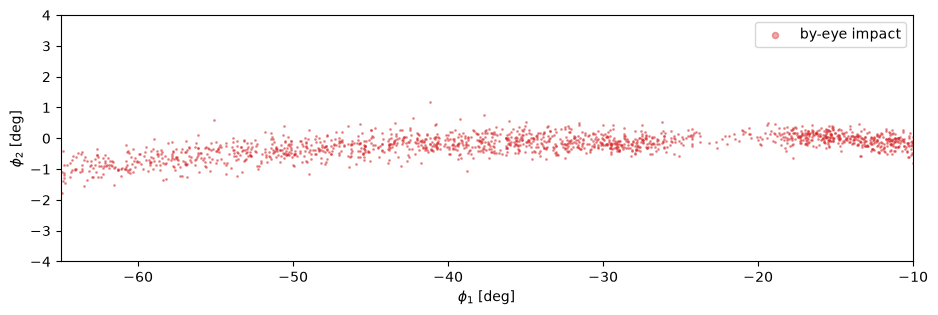

In [32]:
p_eye = dict(phi1_0=jnp.array(-50.0), t_impact=jnp.array(-180.0), #-200
             b=jnp.array(0.2), psi=jnp.array(jnp.deg2rad(210.)),
             wspeed=jnp.array(.4*sigma_sub), wpar_frac=jnp.array(.7), #.4, .7
             log10m=jnp.array(7.2), a=jnp.array(.1))

sub_pot = build_subhalo(p_eye)
stream_eye = perturbed_stream(p_eye, sub_pot)
p1_eye, p2_eye = get_phi12_from_stream(stream_eye)

fig, ax = plt.subplots(figsize=(11, 3.2))
#ax.scatter(phi1_data, phi2_data, s=5, color="k", label="data")
ax.scatter(p1_eye, p2_eye, s=1.2, color="tab:red", alpha=0.4, label="by-eye impact", rasterized=True)
ax.set_xlim(-65, -10); ax.set_ylim(-4, 4)
ax.set_xlabel(r"$\phi_1$ [deg]"); ax.set_ylabel(r"$\phi_2$ [deg]"); ax.legend(markerscale=4)
plt.show()


In [ ]:
from streamsculptor.tnfw_analytic import TNFWSubhaloLinePotential #best model we have/truncated 

X,V = get_impact_params(p_eye)

pot_line_tnfw = TNFWSubhaloLinePotential.from_infall(
    m_infall=jnp.array([2e7]), c_infall=jnp.array([120.0]), z_infall=jnp.array([10.0]), f_bound=jnp.array([.3]),
    subhalo_x0=X[None], subhalo_v=V[None], subhalo_t0=p_eye['t_impact'][None],
    t_window=250.0,
    )

stream_tnfw = perturbed_stream(p_eye,pot_line_tnfw)

p1_tnfw, p2_tnfw = get_phi12_from_stream(stream_tnfw)


fig, ax = plt.subplots(figsize=(11, 3.2))
#ax.scatter(phi1_data, phi2_data, s=5, color="k", label="data")
ax.scatter(p1_tnfw, p2_tnfw, s=1.2, color="tab:red", alpha=1.0, rasterized=True)
ax.set_xlim(-65, -10)
ax.set_ylim(-4, 4)
ax.set_xlabel(r"$\phi_1$ [deg]"); ax.set_ylabel(r"$\phi_2$ [deg]"); ax.legend(markerscale=4)
plt.show()

In [ ]:
# cycle through a few z_infall
z_infall_high = 10.0
z_infall_low = 0.5
z_infall_trial = jnp.logspace(jnp.log10(z_infall_high),jnp.log10(z_infall_low),4)
p1_tnfw_arr = np.zeros((len(p1_tnfw),len(z_infall_trial)))
p2_tnfw_arr = np.zeros((len(p1_tnfw),len(z_infall_trial)))
for i in tqdm.tqdm(range(len(z_infall_trial))):
    z_infall = z_infall_trial[i]
    
    pot_line_tnfw = TNFWSubhaloLinePotential.from_infall(
                m_infall=jnp.array([3e7]), c_infall=jnp.array([120.0]), z_infall=z_infall, f_bound=jnp.array([.8]),
                subhalo_x0=X[None], subhalo_v=V[None], subhalo_t0=p_eye['t_impact'][None],
                t_window=250.0,
               
                )

    stream_tnfw = perturbed_stream(p_eye,pot_line_tnfw)

    p1_tnfw, p2_tnfw = get_phi12_from_stream(stream_tnfw)
    p1_tnfw_arr[:,i] = p1_tnfw
    p2_tnfw_arr[:,i] = p2_tnfw

In [ ]:
z_infall_trial

In [ ]:
fig, ax = plt.subplots(figsize=(11, 3.2))

for i in range(len(z_infall_trial)):
  y_stream = p2_tnfw_arr[:, i] - 5 + i * 5
  sc = ax.scatter(p1_tnfw_arr[:, i], y_stream, s=1.2, alpha=1.0, rasterized=True)

  # Find the rightmost point in the stream to anchor the text
  idx_right = np.nanargmax(p1_tnfw_arr[:, i])
  x_pos = -10.5
  y_pos = y_stream[idx_right] + 4.5

  ax.text(
      x_pos,
      y_pos + 0.9,
      rf"$z_{{\rm infall}} = {z_infall_trial[i]:.2f}$",
      color=sc.get_facecolor()[0],
      fontsize=14,
      ha="right",
      va="bottom",
      fontweight="medium",
  )

ax.set_xlim(-70, -10)
ax.set_ylim(-8, 15)
ax.set_xlabel(r"$\phi_1$ [deg]")
ax.set_ylabel(r"$\phi_2$ [deg]")
plt.tight_layout()
plt.show()

In [ ]:
from streamsculptor.GenerateImpactParams import ImpactGenerator

ImpactGen = ImpactGenerator(pot=pot,
                            tobs=0.0,
                            stream=stream,
                            stream_phi1=phi1_model,
                            phi1_bounds=[-80.,20.],
                            tImpactBounds=[-t_age,0.0],
                            phi1window=.8,
                            NumImpacts=20,
                            bImpact_bounds=[0,.1],
                            stripping_times=jnp.hstack([ts[:-1],ts[:-1]]),
                            prog_today=prog_wtoday,
                            seednum=2332)#22

ImpactDict = ImpactGen.get_subhalo_ImpactParams()
print(ImpactDict.keys())

In [ ]:
ImpactDict['CartesianImpactParams']

In [ ]:
ImpactDict['ImpactFrameParams']

In [ ]:
@jax.jit
def gen_perturbed_stream(m, rs):
    """
    Generate a perturbed stream given 
    an array of subhalo masses and scale radii. 
    Outputs N x 6 array [kpc, kpc/Myr]
    """
    pot_SH = potential.SubhaloLinePotential(m=m,
                                            a=rs,
                                            subhalo_x0=ImpactDict['CartesianImpactParams'][:,:3],
                                            subhalo_v=ImpactDict['CartesianImpactParams'][:,3:],
                                            subhalo_t0=ImpactDict['ImpactFrameParams']['tImpact'],
                                            t_window=jnp.array([200.0]),
                                            units=usys)

    pot_total = potential.Potential_Combine([pot, pot_SH], units=usys)

    # Do NOT fix the prog: perturbed past IC via backward integration in base + subhalos
    IC_pert = pot_total.integrate_orbit(w0=prog_wtoday, t0=0.0, t1=-t_age,
                                        ts=jnp.array([-t_age]), max_steps=5_000).ys[0]

    l, t = ssc.gen_stream_Chen25(pot_base=pot, pot_pert=pot_SH, prog_w0=IC_pert, ts=ts,
                                 Msat=1e4, key=jax.random.PRNGKey(532), method="vmap",
                                 max_steps=5_000, atol=1e-6, rtol=1e-6,
                                 solver=diffrax.Dopri8(), dtmin=.1)
    return jnp.vstack([l, t])

In [ ]:
m = jnp.ones(20)*5e6
rs = jnp.ones(20)*.1
perturbed_stream = gen_perturbed_stream(m, rs)

In [ ]:
phi1_pert, phi2_pert = get_phi12_from_stream(perturbed_stream[:,:3])

fig, ax = plt.subplots(1,1)
fig.set_size_inches(8,8)
ax.scatter(phi1_pert, phi2_pert, s=.2, color='grey')

ax.tick_params(axis='both', which='major', labelsize=14., length=8)
ax.tick_params(axis='both', which='minor', length=3)
ax.set_ylim(-5,5)
ax.set_xlim(-80,20)
ax.set_xlabel(r'$\phi_1$ [deg]', fontsize=20)
ax.set_ylabel(r'$\phi_2$ [deg]', fontsize=20)
ax.set_aspect('equal')